# Assignment 3 — Module 3: Evolutionary and Swarm Optimization


## Practical 9: Differential Evolution

### Aim
To implement a simple Differential Evolution (DE) algorithm for solving an optimization problem using Python.

### Theory
**Differential Evolution** creates trial vectors by adding a scaled difference of population members to a third member. We use the classic **DE/rand/1/bin** strategy:

1. **Mutation:** $\mathbf{v}_i = \mathbf{x}_{r_1} + F(\mathbf{x}_{r_2} - \mathbf{x}_{r_3})$ with $r_1, r_2, r_3$ distinct and different from $i$.
2. **Crossover:** each gene is taken from $\mathbf{v}_i$ with probability $CR$ (at least one gene always comes from $\mathbf{v}_i$).
3. **Selection:** the trial replaces $\mathbf{x}_i$ only if it is at least as good.

We apply DE to the same Rastrigin function used in Practical 8 so the two algorithms can be compared.

### DE implementation

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def rastrigin(x):
    return 10*len(x) + np.sum(x**2 - 10*np.cos(2*np.pi*x))

def differential_evolution(func, dim=5, np_size=30, gens=200, F=0.8, CR=0.9,
                           low=-5.12, high=5.12, seed=0):
    rng = np.random.default_rng(seed)
    pop = rng.uniform(low, high, (np_size, dim))
    fit = np.array([func(x) for x in pop])
    history = []

    for _ in range(gens):
        for i in range(np_size):
            # choose three distinct indices, all different from i
            candidates = [j for j in range(np_size) if j != i]
            r1, r2, r3 = rng.choice(candidates, 3, replace=False)
            # mutation (DE/rand/1)
            mutant = pop[r1] + F * (pop[r2] - pop[r3])
            mutant = np.clip(mutant, low, high)
            # binomial crossover
            cross = rng.random(dim) < CR
            cross[rng.integers(dim)] = True      # guarantee one gene from mutant
            trial = np.where(cross, mutant, pop[i])
            # selection
            f_trial = func(trial)
            if f_trial <= fit[i]:
                pop[i], fit[i] = trial, f_trial
        history.append(fit.min())
    best = pop[np.argmin(fit)]
    return best, fit.min(), history

best_x, best_val, hist = differential_evolution(rastrigin)
print("Best position :", np.round(best_x, 4))
print("Best f(x)     :", f"{best_val:.6f}")

Best position : [-0.0244  0.0845 -0.     -0.064  -0.0324]
Best f(x)     : 2.512983


### Convergence plot

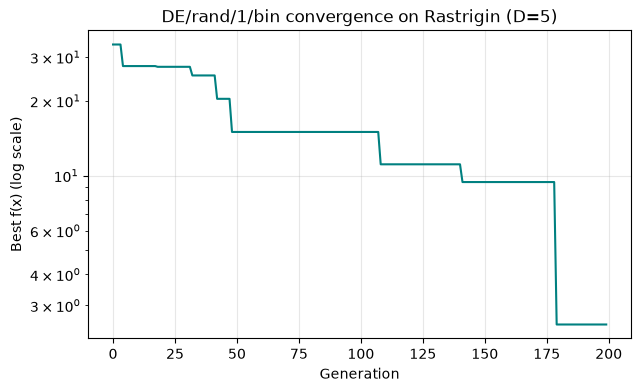

In [2]:
plt.figure(figsize=(7, 4))
plt.plot(hist, color='teal')
plt.yscale('log')
plt.xlabel('Generation'); plt.ylabel('Best f(x) (log scale)')
plt.title('DE/rand/1/bin convergence on Rastrigin (D=5)')
plt.grid(True, alpha=0.3); plt.show()

### Sensitivity to F and CR

In [3]:
print("Mean best f(x) over 10 runs (gens = 200):")
for F in [0.5, 0.8]:
    for CR in [0.1, 0.9]:
        vals = [differential_evolution(rastrigin, F=F, CR=CR, seed=s)[1] for s in range(10)]
        print(f"  F={F}, CR={CR}: {np.mean(vals):.4f}")

Mean best f(x) over 10 runs (gens = 200):
  F=0.5, CR=0.1: 0.0000
  F=0.5, CR=0.9: 2.0300
  F=0.8, CR=0.1: 0.0000
  F=0.8, CR=0.9: 5.8903


### Observation
- The best value decreases steadily, with occasional plateaus where the population explores before finding a better basin.
- The sensitivity table shows that a low crossover rate ($CR=0.1$) reaches the optimum $f=0$ in every run, while $CR=0.9$ performs much worse. Rastrigin is separable, so changing one variable at a time works best; a high $CR$ changes many genes at once and disrupts good solutions.
- The scaling factor $F$ controls step size; on this problem the effect of $F$ is smaller than the effect of $CR$.
- Compared with the PSO run in Practical 8, DE usually reaches low values with a simple, parameter-light update rule.

### Conclusion
Implemented DE/rand/1/bin with mutation, binomial crossover and greedy selection, and checked how the control parameters $F$ and $CR$ affect performance on Rastrigin.